<a href="https://colab.research.google.com/github/LeonimerMelo/CNNs/blob/Convolutional-Neural-Networks/CNN_MNIST_digits_optimizers_comparison_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from tensorflow import keras
import keras # Import the Keras library
from keras.datasets import mnist # Load the MNIST dataset
from keras.models import Sequential # Initialize a sequential model
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras import backend
import numpy as np

In [2]:
# Load the MNIST dataset from Keras
(x_train, y_train), (x_test, y_test) = mnist.load_data()
# Print the shape of the training and test data
print(x_train.shape, y_train.shape)
# Reshape the training and test data to 4 dimensions
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)
print(x_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28) (60000,)
(60000, 28, 28, 1)


In [3]:
# Convert the labels to categorical format
y_train = keras.utils.to_categorical(y_train)
y_test = keras.utils.to_categorical(y_test)
print(x_train.max(), x_train.min())
# Convert the pixel values to floats between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
print(x_train.max(), x_train.min())

255 0
1.0 0.0


In [16]:
y_test[0]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

In [4]:
backend.clear_session()
model = Sequential()
model.add(Input((28,28,1))) # Define the input shape
model.add(Conv2D(kernel_size=5, filters=16, activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(10, activation='softmax'))
initial_weights = model.get_weights()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        23,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,466 (91.66 KB)

 Trainable params: 23,466 (91.66 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(loss='categorical_crossentropy', optimizer='SGD', metrics=['accuracy'])

In [6]:
def processing_time(start_t, finish_t):
  tot_seg = finish_t - start_t
  t_min = tot_seg // 60
  t_seg = tot_seg % 60
  print("\nTempo de treinamento da rede:%2im%2is"% (t_min, t_seg))

In [7]:
import time
start_time = time.process_time()
model.set_weights(initial_weights)
h=model.fit(x_train, y_train, batch_size=32, epochs=15, verbose=1, validation_split=0.1)
processing_time(start_time, time.process_time())

Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.8452 - loss: 0.5676 - val_accuracy: 0.9263 - val_loss: 0.2594
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9191 - loss: 0.2788 - val_accuracy: 0.9445 - val_loss: 0.1974
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9395 - loss: 0.2132 - val_accuracy: 0.9612 - val_loss: 0.1533
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9523 - loss: 0.1675 - val_accuracy: 0.9665 - val_loss: 0.1277
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9607 - loss: 0.1377 - val_accuracy: 0.9727 - val_loss: 0.1069
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9665 - loss: 0.1179 - val_accuracy: 0.9767 - val_loss: 0.0936
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9710 - loss: 0.1043 - val_accuracy: 0.9783 - val_loss: 0.0876
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9739 - loss: 0.0941 -

In [8]:
import matplotlib.pyplot as plt
# Função para plotar os gráficos da acurácia (accuracy) e da perda (loss)
def plot_acc_loss(h,model):
  plt.figure(figsize = (11,5))
  plt.subplot(1,2,1)
  plt.plot(h.history['loss'], label = 'Treino')
  plt.plot(h.history['val_loss'], label = 'Validação')
  plt.xlabel('Épocas')
  plt.ylabel('Função Custo')
  plt.title('loss')
  plt.xticks()
  plt.yticks()
  plt.legend()
  plt.grid()
  plt.subplot(1,2,2)
  plt.plot(h.history['accuracy'], label = 'Treino')
  plt.plot(h.history['val_accuracy'], label = 'Validação')
  plt.xlabel('Épocas')
  plt.ylabel('Acurácia')
  plt.title('accuracy')
  plt.xticks()
  plt.yticks()
  plt.legend()
  plt.tight_layout()
  plt.grid()
  plt.suptitle('model: '+str(model))
  plt.subplots_adjust(top=0.88)
  plt.show()

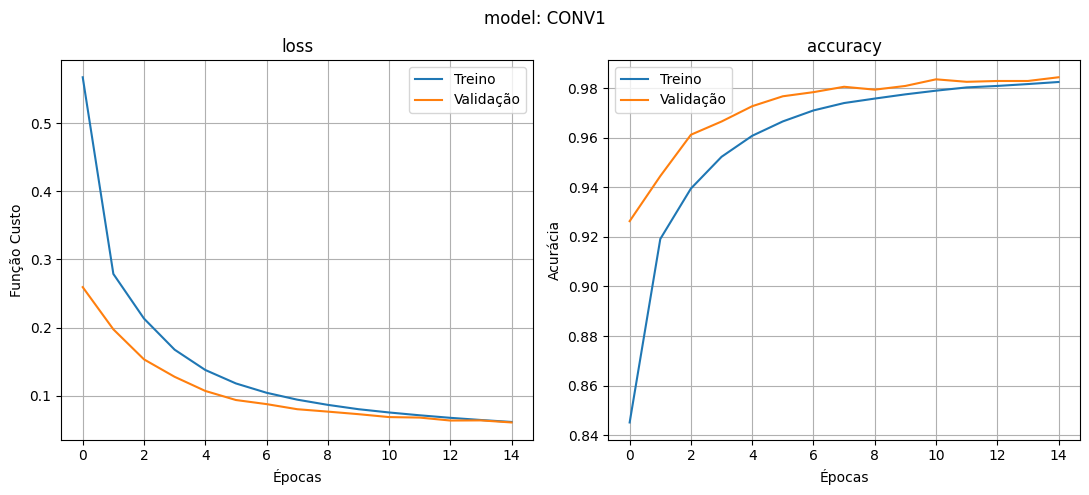

In [9]:
plot_acc_loss(h,'CONV1')

In [10]:
# utilizando o modelo para fazer as predições
y_pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [11]:
y_pred.shape

(10000, 10)

In [12]:
y_pred[0]

array([1.5316293e-07, 3.1020289e-08, 8.4742378e-06, 1.1339930e-04,
       2.3878248e-09, 6.6750431e-08, 2.1934123e-12, 9.9985063e-01,
       6.9242094e-07, 2.6492187e-05], dtype=float32)

In [13]:
y_predict = np.argmax(y_pred,axis=1)

In [ ]:
y_predict

array([7, 2, 1, ..., 4, 5, 6])

In [14]:
y_test.shape

(10000, 10)

In [18]:
y_test[0]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

In [19]:
y_test_ = np.argmax(y_test,axis=1)

In [20]:
y_test_

array([7, 2, 1, ..., 4, 5, 6])

In [21]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test_, y_predict)

0.9827

In [24]:
"""
  Builds a CNN model for MNIST digit classification.

  Args:
    optimizer: The optimizer to use for training the model.

  Returns:
    A compiled Keras model.
  """

def build_model(optimizer):
    model = Sequential()
    model.add(Input((28,28,1))) # Define the input shape
    model.add(Conv2D(32, 5, activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    #model.add(Dropout(0.25))
    model.add(Conv2D(64, (5, 5), activation='relu'))
    model.add(MaxPooling2D((2, 2)))
    #model.add(Dropout(0.25))
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))
    #model.add(Dropout(0.5))
    model.add(Dense(10, activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])
    return model

In [25]:
# Define the batch size
batch_size = 32
# Define the number of epochs to train the model for
epochs = 15
optimizers=['Adagrad','Adam','SGD', 'RMSprop']
histories ={opt:build_model(opt).fit(x_train,y_train,batch_size=batch_size,
  epochs=epochs,verbose=1,validation_data=(x_test,y_test)) for opt in optimizers}

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.7382 - loss: 1.0420 - val_accuracy: 0.8995 - val_loss: 0.3706
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9082 - loss: 0.3255 - val_accuracy: 0.9256 - val_loss: 0.2621
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9265 - loss: 0.2540 - val_accuracy: 0.9403 - val_loss: 0.2150
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9371 - loss: 0.2164 - val_accuracy: 0.9489 - val_loss: 0.1859
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9447 - loss: 0.1908 - val_accuracy: 0.9538 - val_loss: 0.1669
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9499 - loss: 0.1721 - val_accuracy: 0.9566 - val_loss: 0.1520
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9542 - loss: 0.1575 - val_accuracy: 0.9626 - val_loss: 0.1385
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9571 - loss: 0.1457 -


 Adagrad


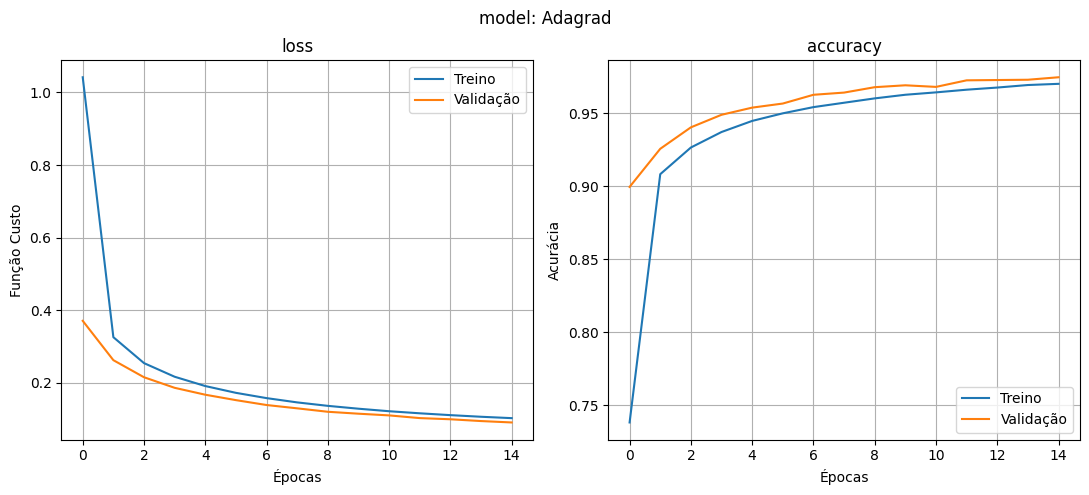


 Adam


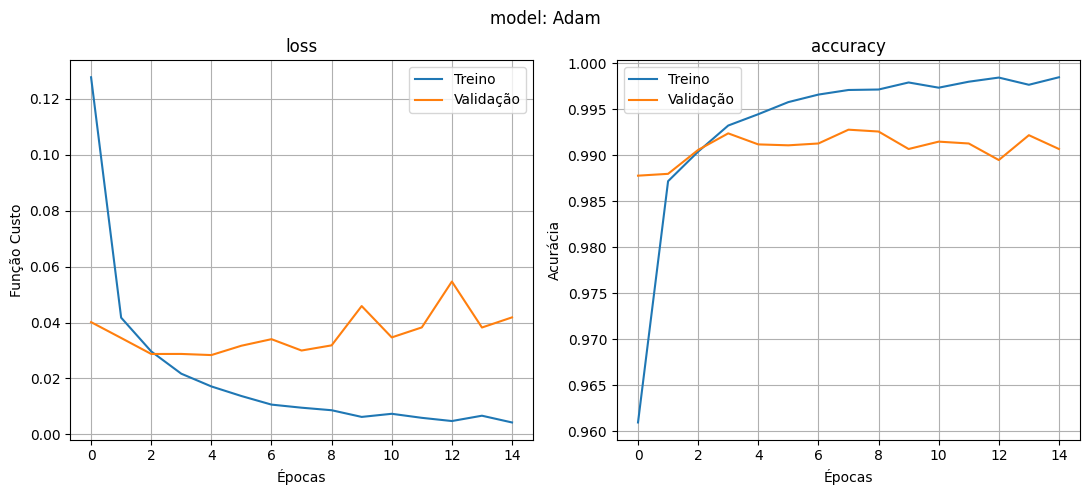


 SGD


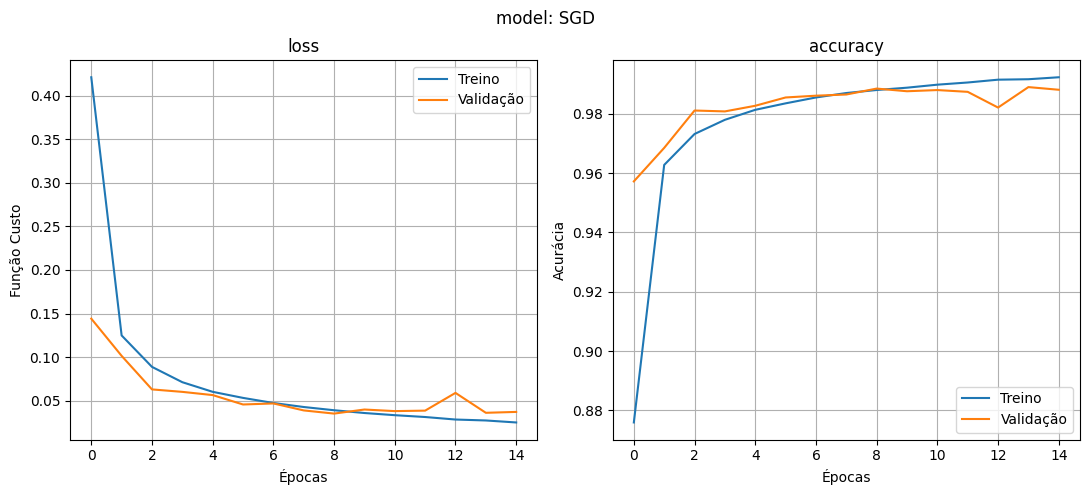


 RMSprop


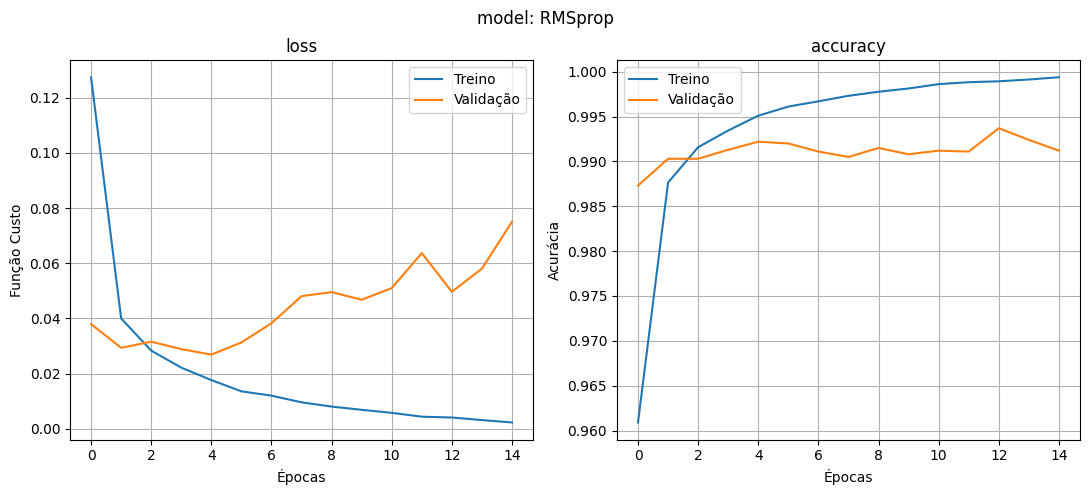

In [26]:
for key, value in histories.items():
  print('\n',key)
  plot_acc_loss(value, key)

##Exercícios
1. Proceda a sintonia dos hiperparâmetros da rede (batch_size, epochs) na tentativa de uma melhor eficiência nos resultados dos treinamentos.
1. Introduza camadas de regularização (dropout e outros) e compare dos resultados.
1. Mude o learning_rate dos otimizadores e compare os resultados.
1. Compare os resultados obtidos aqui com o modelo de rede CNN com os obtidos nos notebooks anteriores com a rede Deep Learning fully conected. Analise e comentes os resultados.

##Referências
[1] https://www.sciencedirect.com/science/article/pii/S2214785321013316

[2] https://link.springer.com/article/10.1007/s11045-022-00819-x

[3] https://arxiv.org/pdf/1910.05446

[4] https://medium.com/geekculture/a-2021-guide-to-improving-cnns-optimizers-adam-vs-sgd-495848ac6008

[5] https://towardsdatascience.com/neural-network-optimization-algorithms-1a44c282f61d